# Local Matching for Kaggle

Finds duplicate records **within** the normalized Kaggle airport dataset (`kaggleNormalized.csv`): the same real-world airport stored as more than one row.

Candidate pairs are generated by three complementary blocking rules, and the union of their candidates is scored:

- **Rule A: `countryCode` + distinguishing `name` token.** Two records are candidates if they are in the same country and share a `name` token that is not a common word. Needs a `countryCode` and at least one distinguishing token.
- **Rule B: geographic grid (H3).** Two records are candidates if they lie in the same or in adjacent H3 cells, regardless of name or country. Covers records with generic names or a missing / wrong `countryCode`.
- **Rule C: ICAO / IATA code.** Two records are candidates if they share the same non-null ICAO or IATA code. Kaggle-specific: both codes are assigned globally uniquely — if two rows carry the same code, they almost certainly describe the same airport.

A pair only needs to be found by one of the three rules.

**Steps**

1. Load the normalized dataset
2. Blocking Rule A: `countryCode` + distinguishing `name` tokens
3. Blocking Rule B: geographic grid (H3)
4. Blocking Rule C: ICAO / IATA code
5. Combine and filter candidates: union of all three rules, no self-pairs, no reversed duplicates
6. Coverage check: records reached by neither rule
7. Per-attribute comparators (name, city, geo distance, icao, iata)
8. Score candidates with `RuleBasedMatcher`
9. Score distribution
10. Manual review of high-scoring candidates

**Kaggle-specific notes:**
- Dataset is smaller than Wikidata (6 391 records) → `COMMON_TOKEN_THRESHOLD = 10` (vs 20 for Wikidata)
- `city` often contains `"city state"` after normalization (e.g. `"clovis new mexico"`) — weighted lower
- Records at `(0.0, 0.0)` have missing coordinates, not a real location — H3 blocks these together; filtered out before Rule B
- Both `countryCode` and `countryName` are present; `countryCode` (ISO alpha-2) is used as the blocking key

In [1]:
from collections import Counter
from pathlib import Path
import math

import h3
import matplotlib.pyplot as plt
import pandas as pd

from PyDI.entitymatching import TokenBlocker, RuleBasedMatcher
from PyDI.entitymatching import StringComparator
from PyDI.entitymatching.base import BaseComparator

/Users/I569494/Development/Uni Mannheim/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the normalized dataset

In [2]:
DATA_DIR = Path("../../data/normalized_outputs")
INPUT_CSV = DATA_DIR / "kaggleNormalized.csv"

df = pd.read_csv(INPUT_CSV, keep_default_na=False, na_values=[""])
df.attrs["source"] = "kaggle"

print(f"Loaded {len(df)} records")
print(f"Columns: {list(df.columns)}")
df.head(5)

Loaded 6391 records
Columns: ['id', 'name', 'iata', 'icao', 'lat', 'lon', 'countryCode', 'countryCodeA3', 'countryName', 'city', 'cityIata', 'timezone']


,id,name,iata,icao,lat,lon,countryCode,countryCodeA3,countryName,city,cityIata,timezone
0,kg_1,pilanesberg international,NTY,FAPN,-25.333822,27.173358,ZA,ZAF,south africa,sun city,NTY,Africa/Johannesburg
1,kg_2,clovis municipal,CVN,KCVN,34.425139,-103.079278,US,USA,united states of america,clovis new mexico,CVN,America/Denver
2,kg_3,cannon air force base,CVS,KCVS,34.382775,-103.322147,US,USA,united states of america,clovis new mexico,CVN,America/Denver
3,kg_4,scammon bay airport,SCM,PACM,61.845278,-165.571389,US,USA,united states of america,scammon bay alaska,SCM,America/Nome
4,kg_5,kapit,KPI,NaN,2.017000,112.950000,MY,MYS,malaysia,kapit,KPI,Asia/Kuching


## Blocking Rule A: `countryCode` + distinguishing `name` tokens

- Goal: generate candidate duplicate pairs by self-blocking. Generic words in `name` (`airport`, `international`, common geographic words, ...) must not be used as blocking keys because they would create huge blocks with thousands of unrelated records.

- Method: `TokenBlocker` on `name`.
  - Tokens that appear in more than `COMMON_TOKEN_THRESHOLD` distinct names are treated as non-distinguishing and excluded; this list is derived from the data (document frequency).
  - `countryCode` is prepended to each remaining token (e.g. `"US::scammon"`), so a pair is a candidate only if the two records share a distinguishing token **and** have the same country.

- `COMMON_TOKEN_THRESHOLD = 10` (smaller than Wikidata's 20 because Kaggle has ~6 400 records vs ~24 900).

### Generate blocking key column

In [3]:
COMMON_TOKEN_THRESHOLD = 10

token_doc_freq = Counter()
for name in df["name"].dropna():
    token_doc_freq.update(set(t for t in name.split() if len(t) >= 2))

COMMON_TOKENS = {t for t, c in token_doc_freq.items() if c > COMMON_TOKEN_THRESHOLD}
print(f"Excluding {len(COMMON_TOKENS)} tokens that each appear in more than {COMMON_TOKEN_THRESHOLD} names")
print(f"Sample common tokens excluded: {sorted(COMMON_TOKENS)[:20]}")

def blocking_tokenizer(text):
    if not isinstance(text, str):
        return []
    return [t for t in text.split() if len(t) >= 2 and t not in COMMON_TOKENS]

print("\nExample tokens kept for blocking:")
for name in df["name"].dropna().head(5):
    print(f"  {name!r:45s} -> {blocking_tokenizer(name)}")

no_tokens_left = df["name"].apply(lambda n: len(blocking_tokenizer(n)) == 0)
print(f"\n{no_tokens_left.sum()} records ({no_tokens_left.mean():.1%}) have no distinguishing token left "
      "and cannot be reached by Rule A.")

Excluding 56 tokens that each appear in more than 10 names
Sample common tokens excluded: ['air', 'airport', 'airstrip', 'army', 'base', 'bay', 'beach', 'bus', 'carlos', 'central', 'city', 'county', 'creek', 'falls', 'field', 'force', 'fort', 'general', 'grand', 'harbor']

Example tokens kept for blocking:
  'pilanesberg international'                   -> ['pilanesberg']
  'clovis municipal'                            -> ['clovis']
  'cannon air force base'                       -> ['cannon']
  'scammon bay airport'                         -> ['scammon']
  'kapit'                                       -> ['kapit']

84 records (1.3%) have no distinguishing token left and cannot be reached by Rule A.


### Implement Blocking to generate candidate pairs

In [4]:
def make_blocking_text(row):
    if pd.isna(row["countryCode"]) or pd.isna(row["name"]):
        return None
    return f"{row['countryCode']}||{row['name']}"

df["name_with_country"] = df.apply(make_blocking_text, axis=1)

def country_scoped_tokenizer(text):
    if not isinstance(text, str):
        return []
    country, _, name = text.partition("||")
    return [f"{country}::{t}" for t in blocking_tokenizer(name)]

blocker_token = TokenBlocker(
    df_left=df,
    df_right=df,
    column="name_with_country",
    id_column="id",
    tokenizer=country_scoped_tokenizer,
)

candidates_token = blocker_token.materialize()
print(f"Raw candidate pairs from token blocking: {len(candidates_token)}")

Raw candidate pairs from token blocking: 8945


### Deduplication of pairs
- Goal: remove the noise self-blocking produces.
- Method: drop `id1 == id2`, and keep one canonical direction per pair (`id1 < id2`) to drop `(A,B)`/`(B,A)` duplicates.

In [5]:
candidates_token = candidates_token[candidates_token["id1"] != candidates_token["id2"]].copy()

swap = candidates_token["id1"] > candidates_token["id2"]
candidates_token.loc[swap, ["id1", "id2"]] = candidates_token.loc[swap, ["id2", "id1"]].values
candidates_token = candidates_token.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)

print(f"Candidate pairs after filtering: {len(candidates_token)}")
candidates_token.head(5)

Candidate pairs after filtering: 1326


,id1,id2
0,kg_6,kg_803
1,kg_5819,kg_6
2,kg_5819,kg_803
3,kg_11,kg_2170
4,kg_11,kg_2387


## Blocking Rule B: Geographic grid (H3)

- Goal: find duplicate pairs that Rule A cannot reach — records whose names are generic or share no distinguishing token, or whose `countryCode` is missing or inconsistent.

- Method: map each record to an [H3](https://h3geo.org/) hexagonal cell at resolution `RESOLUTION = 9` (average edge length ≈ 174 m) and use `TokenBlocker` on the H3 cell IDs.
  - Each record emits **7 tokens**: the cell containing it plus its 6 neighboring cells (`h3.grid_disk(cell, 1)`). Two records in the same or adjacent cells always share a token.
  - `countryCode` is deliberately **not** part of the token — this also covers records with a missing or inconsistent country code.
  - Records without coordinates, **or at `(0.0, 0.0)`** (missing coordinates in Kaggle), emit no tokens.

- Implementation: `TokenBlocker`'s tokenizer only sees one column's text; the H3 tokens are precomputed per record and looked up by `id`.

### Define H3 grid token generation function

In [6]:
RESOLUTION = 9

def geo_h3_tokens(row):
    lat, lon = row["lat"], row["lon"]
    # Filter out missing coordinates AND the Kaggle-specific (0, 0) sentinel
    if pd.isna(lat) or pd.isna(lon) or (lat == 0.0 and lon == 0.0):
        return []
    center = h3.latlng_to_cell(lat, lon, RESOLUTION)
    return list(h3.grid_disk(center, 1))

print("Test: Tokyo Narita (35.7647, 140.3864)")
print(geo_h3_tokens({"lat": 35.7647, "lon": 140.3864}))

Test: Tokyo Narita (35.7647, 140.3864)
['892f5ac4c7bffff', '892f5ac4c4fffff', '892f5ac4eb7ffff', '892f5ac4c6bffff', '892f5ac4c63ffff', '892f5ac4c73ffff', '892f5ac4c47ffff']


### Generate `geo_grid_tokens` column

In [7]:
df["geo_grid_tokens"] = df.apply(geo_h3_tokens, axis=1)
grid_token_lookup = df.set_index("id")["geo_grid_tokens"].to_dict()

no_coords = df["geo_grid_tokens"].apply(len) == 0
print(f"{no_coords.sum()} records have no valid coordinates (missing or 0,0) → not reachable by Rule B")

319 records have no valid coordinates (missing or 0,0) → not reachable by Rule B


### Implement Blocking to generate candidate pairs

In [8]:
def grid_tokenizer(record_id):
    return grid_token_lookup.get(record_id, [])

df["id_as_text"] = df["id"]

blocker_geo = TokenBlocker(
    df_left=df,
    df_right=df,
    column="id_as_text",
    id_column="id",
    tokenizer=grid_tokenizer,
)

### Deduplication of pairs

In [9]:
candidates_geo = blocker_geo.materialize()
print(f"Raw candidate pairs from geo blocking: {len(candidates_geo)}")

candidates_geo = candidates_geo[candidates_geo["id1"] != candidates_geo["id2"]].copy()
swap = candidates_geo["id1"] > candidates_geo["id2"]
candidates_geo.loc[swap, ["id1", "id2"]] = candidates_geo.loc[swap, ["id2", "id1"]].values
candidates_geo = candidates_geo.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)

print(f"Candidate pairs after filtering: {len(candidates_geo)}")

Raw candidate pairs from geo blocking: 6196
Candidate pairs after filtering: 62


## Blocking Rule C: ICAO / IATA code

- Goal: catch the case where the same real airport appears twice in Kaggle with the same ICAO or IATA code but slightly different name, city, or coordinates.

- Method: a direct pandas self-join on `icao` and on `iata`. No TokenBlocker needed — there is no tokenization, just exact equality.
  - ICAO and IATA are internationally unique identifiers. Two records sharing the same non-null code are almost certainly the same airport.
  - Records without a code naturally emit no candidates for that code.
  - Pairs found by Rule C typically score very high on the `icao`/`iata` comparator and are strong duplicate candidates regardless of name or coordinate differences.

In [10]:
icao_df = df[df["icao"].notna()][["id", "icao"]].copy()
icao_pairs = icao_df.merge(icao_df, on="icao", suffixes=("1", "2"))[["id1", "id2"]]

iata_df = df[df["iata"].notna()][["id", "iata"]].copy()
iata_pairs = iata_df.merge(iata_df, on="iata", suffixes=("1", "2"))[["id1", "id2"]]

candidates_codes = pd.concat([icao_pairs, iata_pairs])
candidates_codes = candidates_codes[candidates_codes["id1"] != candidates_codes["id2"]].copy()
swap = candidates_codes["id1"] > candidates_codes["id2"]
candidates_codes.loc[swap, ["id1", "id2"]] = candidates_codes.loc[swap, ["id2", "id1"]].values
candidates_codes = candidates_codes.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)

print(f"Candidate pairs from ICAO/IATA code blocking: {len(candidates_codes)}")
candidates_codes.head(5)

Candidate pairs from ICAO/IATA code blocking: 0


,id1,id2


## Concatenate candidate pairs from all three blocking rules

In [11]:
candidates = pd.concat([candidates_geo, candidates_token, candidates_codes], axis=0)

candidates = candidates[candidates["id1"] != candidates["id2"]].copy()
swap = candidates["id1"] > candidates["id2"]
candidates.loc[swap, ["id1", "id2"]] = candidates.loc[swap, ["id2", "id1"]].values
candidates = candidates.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)

print(f"All candidate pairs after deduplication: {len(candidates)}")

def pair_set(df_pairs):
    d = df_pairs[df_pairs["id1"] != df_pairs["id2"]]
    return set(zip(d[["id1", "id2"]].min(axis=1), d[["id1", "id2"]].max(axis=1)))

s_token = pair_set(candidates_token)
s_geo = pair_set(candidates_geo)
s_codes = pair_set(candidates_codes)
s_union = s_token | s_geo | s_codes
print(f"Rule A: {len(s_token)} | Rule B: {len(s_geo)} | Rule C: {len(s_codes)} | union: {len(s_union)}")
print(f"Only A: {len(s_token - s_geo - s_codes)} | Only B: {len(s_geo - s_token - s_codes)} | Only C: {len(s_codes - s_token - s_geo)}")

All candidate pairs after deduplication: 1373
Rule A: 1326 | Rule B: 62 | Rule C: 0 | union: 1373
Only A: 1311 | Only B: 47 | Only C: 0


## Coverage check: records reached by neither blocking rule

A record is unreachable if it satisfies **all** of:
- Rule A cannot reach it: no `countryCode`, or no distinguishing `name` token left after filtering
- Rule B cannot reach it: no valid coordinates (missing or `(0, 0)`)
- Rule C cannot reach it: no `icao` **and** no `iata`

These records are listed as a known gap.

In [12]:
not_by_rule_a = no_tokens_left | df["countryCode"].isna()
not_by_rule_b = df["geo_grid_tokens"].apply(len) == 0
not_by_rule_c = df["icao"].isna() & df["iata"].isna()

uncovered = not_by_rule_a & not_by_rule_b & not_by_rule_c
print(f"{uncovered.sum()} records unreachable by any rule")
df.loc[uncovered, ["id", "name", "countryCode", "icao", "iata", "lat", "lon"]]

0 records unreachable by any rule


,id,name,countryCode,icao,iata,lat,lon


## Per-attribute comparators

Goal: a similarity score per attribute for each candidate pair.

| Attribute | Comparator | Rationale |
|---|---|---|
| `name` | Jaro-Winkler | Most discriminative; tolerant of small spelling differences |
| `city` | Jaro-Winkler | Lower weight: Kaggle `city` often includes state (`"clovis new mexico"`) |
| `lat`/`lon` | Haversine (max 2 km) | Duplicates of the same airport lie very close; 2 km is tight enough to separate nearby-but-different airports |
| `icao` | Exact, neutral on missing | Strong when present on both sides; neutral (0.5) when either is missing |
| `iata` | Exact, neutral on missing | Same as `icao` |

Note: `icao`/`iata` serve dual roles — as **blocking keys** in Rule C (exact equality) and as **comparators** here (contributing to the weighted score). Using both is fine: a Rule C pair that shares a code will score 1.0 on that comparator and thereby rank higher.

In [13]:
name_comp = StringComparator(column="name", similarity_function="jaro_winkler")
city_comp = StringComparator(column="city", similarity_function="jaro_winkler")


class GeoDistanceComparator(BaseComparator):
    """Haversine great-circle distance → similarity score."""

    def __init__(self, lat_column="lat", lon_column="lon", max_distance_km=2.0):
        super().__init__(name="geo_distance")
        self.lat_column = lat_column
        self.lon_column = lon_column
        self.max_distance_km = max_distance_km

    def compare(self, record1, record2):
        lat1, lon1 = record1.get(self.lat_column), record1.get(self.lon_column)
        lat2, lon2 = record2.get(self.lat_column), record2.get(self.lon_column)
        # treat missing or (0,0) sentinel as neutral
        if (pd.isna(lat1) or pd.isna(lon1) or (lat1 == 0.0 and lon1 == 0.0)
                or pd.isna(lat2) or pd.isna(lon2) or (lat2 == 0.0 and lon2 == 0.0)):
            return 0.5
        distance_km = self._haversine_km(lat1, lon1, lat2, lon2)
        return max(0.0, 1.0 - distance_km / self.max_distance_km)

    @staticmethod
    def _haversine_km(lat1, lon1, lat2, lon2):
        R = 6371.0
        phi1, phi2 = math.radians(lat1), math.radians(lat2)
        dphi = math.radians(lat2 - lat1)
        dlambda = math.radians(lon2 - lon1)
        a = (math.sin(dphi / 2) ** 2
             + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2)
        return 2 * R * math.asin(math.sqrt(a))


geo_comp = GeoDistanceComparator(max_distance_km=2.0)


class CodeComparator(BaseComparator):
    """Exact-match for a code column; neutral (0.5) when either side is missing."""

    def __init__(self, column):
        super().__init__(name=f"{column}_exact")
        self.column = column

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if pd.isna(v1) or pd.isna(v2):
            return 0.5
        return 1.0 if v1 == v2 else 0.0


icao_comp = CodeComparator("icao")
iata_comp = CodeComparator("iata")

comparators = [name_comp, city_comp, geo_comp, icao_comp, iata_comp]
comparator_names = ["name", "city", "geo_distance", "icao", "iata"]

# Sanity check on first candidate pair
row = candidates.iloc[0]
idx = df.set_index("id")
r1, r2 = idx.loc[row["id1"]], idx.loc[row["id2"]]
print(f"Pair: {row['id1']} vs {row['id2']}")
for cname, comp in zip(comparator_names, comparators):
    print(f"  {cname:<15} -> {comp.compare(r1, r2):.3f}")

Pair: kg_202 vs kg_691
  name            -> 0.554
  city            -> 0.534
  geo_distance    -> 0.835
  icao            -> 0.000
  iata            -> 0.000


## Score candidates with `RuleBasedMatcher`

Weighted sum of the five comparator scores. Weights sum to 1.0.

| Attribute | Weight | Rationale |
|---|---|---|
| `name` | 0.35 | Most discriminative attribute |
| `geo_distance` | 0.30 | Same physical location is the strongest duplicate signal |
| `icao` | 0.15 | Strong when present on both sides |
| `iata` | 0.10 | Same as `icao`, less often available |
| `city` | 0.10 | Lowest: Kaggle's city often encodes state, not just city |

`threshold=0.0` keeps every candidate pair; the actual cutoff is chosen from the score distribution below.

In [14]:
weights = [0.35, 0.10, 0.30, 0.15, 0.10]  # name, city, geo_distance, icao, iata

matcher = RuleBasedMatcher()
correspondences, debug_results = matcher.match(
    df_left=df,
    df_right=df,
    candidates=candidates[["id1", "id2"]],
    id_column="id",
    comparators=comparators,
    weights=weights,
    threshold=0.0,
    debug=True,
)

print(f"Scored {len(correspondences)} candidate pairs")
correspondences.head(10)

Scored 1373 candidate pairs


,id1,id2,score,notes
0,kg_202,kg_691,0.497678,comparators=5
1,kg_224,kg_3260,0.643016,comparators=5
2,kg_279,kg_4160,0.659849,comparators=5
3,kg_1390,kg_294,0.735667,comparators=5
4,kg_4514,kg_608,0.770618,comparators=5
5,kg_781,kg_782,0.657832,comparators=5
6,kg_4698,kg_798,0.606302,comparators=5
7,kg_4939,kg_863,0.740217,comparators=5
8,kg_6208,kg_863,0.737089,comparators=5
9,kg_4939,kg_6208,0.725021,comparators=5


## Score distribution

Histogram of all candidate scores — look for a natural gap between likely duplicates and blocking false positives before picking a threshold.

count    1373.000000
mean        0.372995
std         0.112703
min         0.189938
25%         0.284361
50%         0.349460
75%         0.423655
max         0.824433
Name: score, dtype: float64


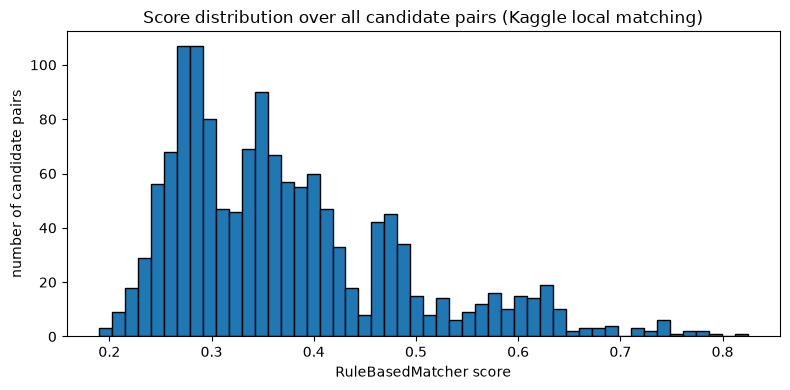

In [15]:
print(correspondences["score"].describe())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(correspondences["score"], bins=50, edgecolor="black")
ax.set_xlabel("RuleBasedMatcher score")
ax.set_ylabel("number of candidate pairs")
ax.set_title("Score distribution over all candidate pairs (Kaggle local matching)")
plt.tight_layout()
plt.show()

## Manual review of high-scoring candidates

List every candidate pair with `score > SCORE_THRESHOLD` alongside `name`, `city`, `icao`, `iata` for manual inspection.

`SCORE_THRESHOLD = 0.65` — chosen from the score distribution: the secondary bump ends around 0.65, after which only the sparse high-confidence tail remains.

In [22]:
SCORE_THRESHOLD = 0.65

name_city_codes = df.set_index("id")[["name", "city", "icao", "iata", "countryCode"]]

review = (
    correspondences[correspondences["score"] > SCORE_THRESHOLD]
    .sort_values("score", ascending=False)
    .join(name_city_codes.add_suffix("1"), on="id1")
    .join(name_city_codes.add_suffix("2"), on="id2")
)

print(f"{len(review)} candidate pairs with score > {SCORE_THRESHOLD}")
review[["id1", "id2", "name1", "name2", "city1", "city2",
        "icao1", "icao2", "iata1", "iata2", "countryCode1", "countryCode2", "score"]]

30 candidate pairs with score > 0.65


,id1,id2,name1,name2,city1,city2,icao1,icao2,iata1,iata2,countryCode1,countryCode2,score
31,kg_4813,kg_4814,sinop airport,sinop airport,sinop,sinop,NaN,LTCM,NOP,SIC,TR,TR,0.824433
10,kg_884,kg_885,siem reap angkor,siem reap,siem reap,siem reap,NaN,VDSR,SAI,REP,KH,KH,0.794375
30,kg_4800,kg_5356,saint augustine airport,saint augustine airport,sagarai,saint augustine florida,NaN,KSGJ,SGJ,UST,PG,US,0.781338
32,kg_5092,kg_5093,huanghua,huanghua international,changsha,changsha,ZGHA,NaN,CSX,HHA,CN,CN,0.780455
4,kg_4514,kg_608,general manuel carlos piar,general manuel carlos piar,ciudad guayana,puerto ordaz,NaN,SVPR,CGU,PZO,VE,VE,0.770618
34,kg_5563,kg_5565,euroairport,euroairport basel mulhouse freiburg,basel mulhouse,basel mulhouse,NaN,NaN,EAP,BSL,FR,FR,0.766092
16,kg_1713,kg_6250,vigo,vigo,vigo,pontevedra,LEVX,NaN,VGO,VBT,ES,ES,0.759358
24,kg_3041,kg_4047,essen railway,essen hbf railway station,goeppingen,essen,NaN,NaN,ZES,ESZ,DE,DE,0.744700
28,kg_3787,kg_4798,scottsdale mncpl,scottsdale airport,phoenix arizona,scottsdale arizona,NaN,KSDL,SCF,ZSY,US,US,0.741856
7,kg_4939,kg_863,augsburg railway,augsburg hbf,aue,itauba,NaN,AUGS,ZAU,AUB,DE,BR,0.740217
